--- shape of dataset ---
(10000, 14)

--- first 5 rows ---
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113

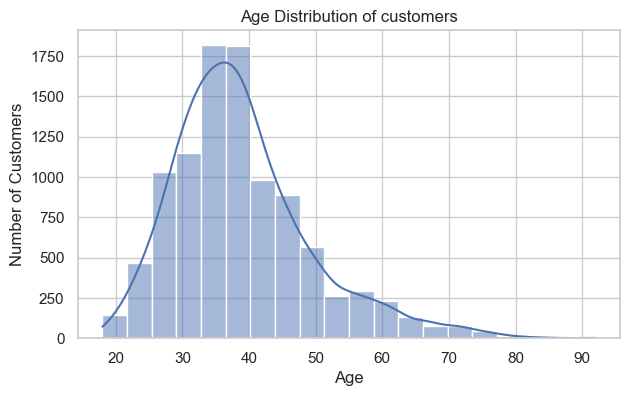


---Average Balance by age ---
   Age      Balance
0   18  79169.57500
1   19  70502.53963
2   20  76038.89000
3   21  75926.88283
4   22  68213.74881


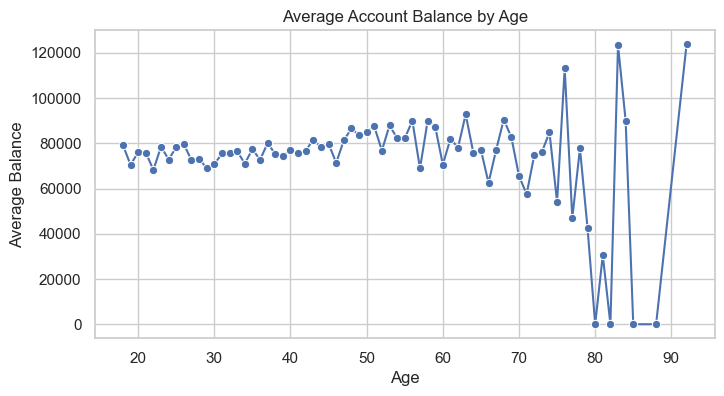

In [2]:
import pandas as pd
df = pd.read_csv('bank customers churn.csv')
print("--- shape of dataset ---")
print(df.shape)
print("\n--- first 5 rows ---")
print(df.head())
print("\n--- dataset info ---")
print(df.info())
print("\n --- statistical summary ---")
print(df.describe())
duplicate_count = df.duplicated().sum()
print(f"number of duplicates rows{duplicate_count}")
df = df.drop_duplicates()
print("\n --- missing values check ---")
print(df.isnull().sum())
print("\n --- data types ---")
print(df.dtypes)
columns_to_drop = ['RowNunmber' , 'Customerid' ,'Surname']
df = df.drop(columns=columns_to_drop , errors= 'ignore')
print("\n--- columns after dropping irrelevant ones ---")
print(df.columns)
print(df.head())
text_columns = ['Geography' , 'Gender']
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
print("--- unnecessary spaces removed successfully from text columns ---")
print("--- unique values in Geography ---")
print(df['Geography'].unique())
print("\n--- unique values in gender ---")
print(df['Gender'].unique())
print("\n--- unique values in Exited ---")
print(df['Exited'].unique())
df = df[(df['Age'] >= 18) & (df['Age'] <= 100)]
df.loc[df['Balance'] < 0, 'Balance'] = 0
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
print(F"Age IQR: {IQR}")
for col in ['Geography', 'Gender']:
    if col in df.columns:
        df[col] = df[col].str.strip().str.title()
print("\n --- valid Exited values ---")
print(df['Exited'].value_counts())
df = df.rename(columns={'NumofProducts': 'Num_of_products', 'HasCrCard':'HasCrCard','IsActiveMember': 'Is_Active_Member', 'EstimatedSalary': 'Estimates_Salary'})
print("\n--- final cleaned columns ---")
print(df.columns)
print("\n--- final shape after cleaning ---")
print(df.shape)
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")
print("\n--- Age Summary---")
print(df['Age'].describe())
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='Age',bins=20, kde=True)
plt.title('Age Distribution of customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()
# insights(Age distribution): Most customers fall in the 30-45 age group.
# Customer count gradually decreases in older age group.
# The distribution is slightly right-skewed with a smaller group above 60.
print("\n---Average Balance by age ---")
age_balance = df.groupby('Age')['Balance'].mean().reset_index()
print(age_balance.head())
plt.figure(figsize=(8, 4))
sns.lineplot(data=age_balance, x='Age', y='Balance', marker='o')
plt.title('Average Account Balance by Age')
plt.xlabel('Age')
plt.ylabel('Average Balance')
plt.show()
#Insights(Average Balance by Age):
# Average account balance varies noticeably across different age groups.
# Certain middle-aged and olde age brackets show higher average balances than younger customers.
# The trend fluctuates across age rather than increasing steadily.
